In [1]:
import torch
from torchvision import datasets, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cpu


In [2]:
transform = transforms.ToTensor()

train_data = datasets.FashionMNIST(
    root="data", train=True, download=True, transform=transform
)

test_data = datasets.FashionMNIST(
    root="data", train=False, download=True, transform=transform
)

print("Training images:", len(train_data))
print("Test images:", len(test_data))

100%|██████████| 26.4M/26.4M [00:01<00:00, 14.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 211kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.94MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 10.4MB/s]

Training images: 60000
Test images: 10000


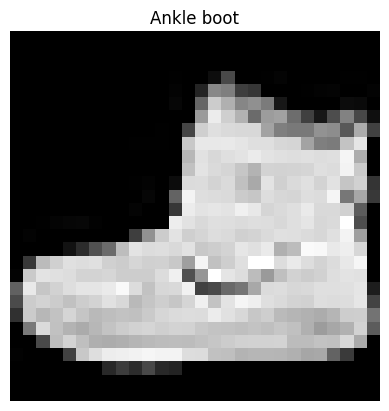

In [3]:
import matplotlib.pyplot as plt

image, label = train_data[0]

plt.imshow(image.squeeze(0), cmap="gray")
plt.title(train_data.classes[label])
plt.axis("off")
plt.show()

In [4]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

In [5]:
from torch import nn

model = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(32 * 7 * 7, 64),
    nn.ReLU(),
    nn.Linear(64, 10),
).to(device)

print(model)

Sequential(
  (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=1568, out_features=64, bias=True)
  (8): ReLU()
  (9): Linear(in_features=64, out_features=10, bias=True)
)


In [6]:
weights = torch.load("fashion_cnn.pth", map_location=device, weights_only=True)
model.load_state_dict(weights)
model.eval()

print("Shared model loaded.")

Shared model loaded.


In [7]:
true_labels = []
predicted_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        scores = model(images.to(device))
        predictions = scores.argmax(dim=1)

        true_labels.extend(labels.tolist())
        predicted_labels.extend(predictions.cpu().tolist())

print("Predictions collected:", len(predicted_labels))

Predictions collected: 10000


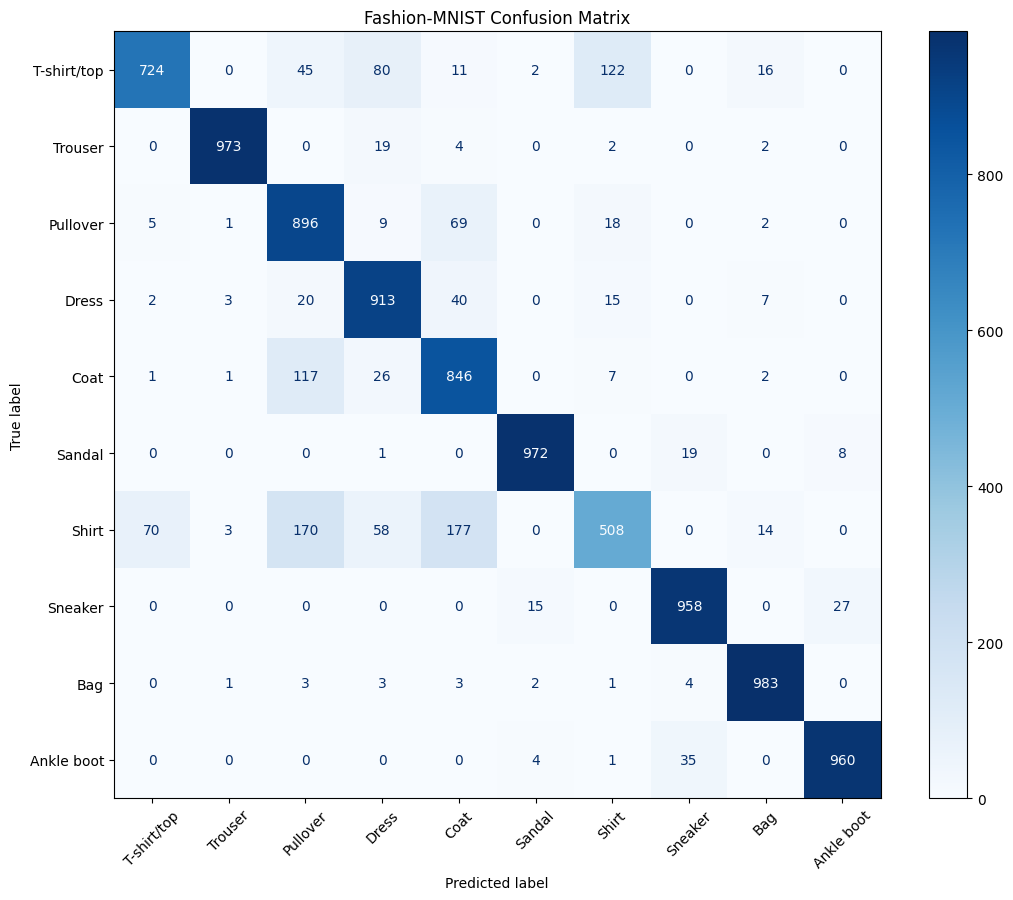

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = test_data.classes
matrix = confusion_matrix(
    true_labels, predicted_labels, labels=range(len(class_names))
)

fig, ax = plt.subplots(figsize=(11, 9))
display = ConfusionMatrixDisplay(matrix, display_labels=class_names)
display.plot(ax=ax, cmap="Blues", xticks_rotation=45, values_format="d")
ax.set_title("Fashion-MNIST Confusion Matrix")
plt.tight_layout()
plt.show()

In [9]:
import numpy as np

errors = matrix.copy()
np.fill_diagonal(errors, 0)  # Exclude correct predictions

row, col = np.unravel_index(errors.argmax(), errors.shape)
print(f"{class_names[row]} → {class_names[col]}: {errors[row, col]} images")

Shirt → Coat: 177 images


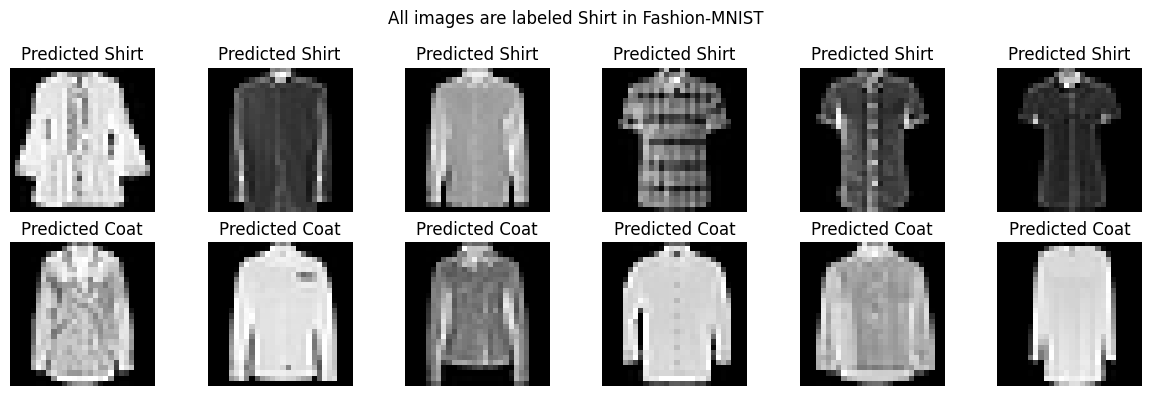

In [10]:
actual = np.array(true_labels)
predicted = np.array(predicted_labels)

correct_shirts = np.flatnonzero((actual == row) & (predicted == row))
shirts_called_coats = np.flatnonzero((actual == row) & (predicted == col))

rng = np.random.default_rng(42)
fig, axes = plt.subplots(2, 6, figsize=(12, 4))

for plot_row, indices, title in [
    (0, correct_shirts, "Predicted Shirt"),
    (1, shirts_called_coats, "Predicted Coat"),
]:
    for ax, index in zip(axes[plot_row], rng.choice(indices, 6, replace=False)):
        image, _ = test_data[int(index)]
        ax.imshow(image.squeeze(0), cmap="gray", vmin=0, vmax=1)
        ax.set_title(title)
        ax.axis("off")

fig.suptitle("All images are labeled Shirt in Fashion-MNIST")
plt.tight_layout()
plt.show()

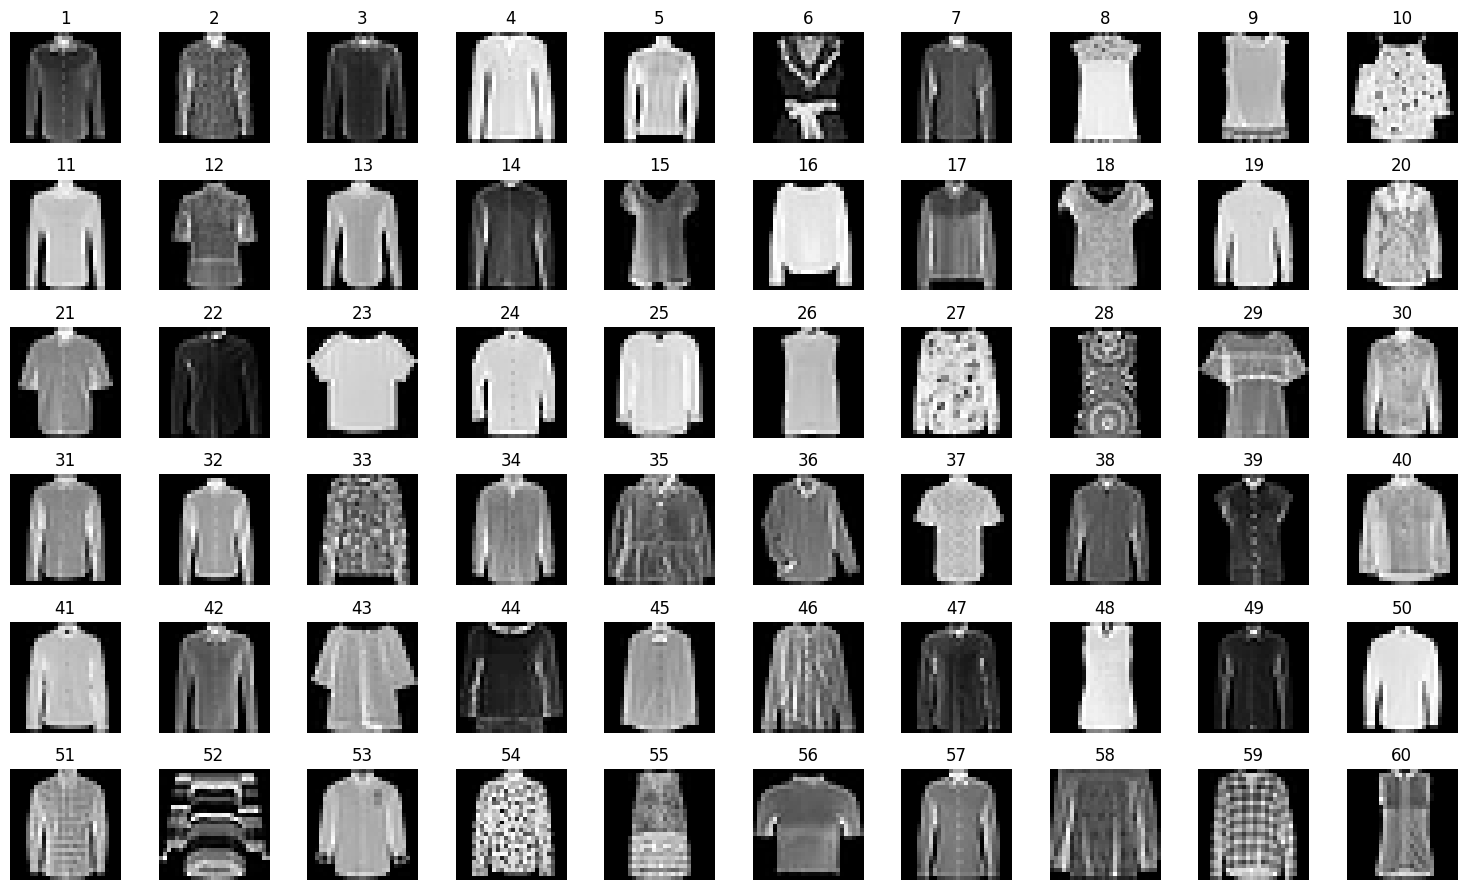

In [11]:
shirt_indices = np.flatnonzero(actual == class_names.index("Shirt"))
sample_indices = np.random.default_rng(123).choice(
    shirt_indices, size=60, replace=False
)

fig, axes = plt.subplots(6, 10, figsize=(15, 9))
for number, (ax, index) in enumerate(zip(axes.flat, sample_indices), start=1):
    image, _ = test_data[int(index)]
    ax.imshow(image.squeeze(0), cmap="gray", vmin=0, vmax=1)
    ax.set_title(str(number))
    ax.axis("off")

plt.tight_layout()
plt.show()

In [14]:
shirt_indices = np.flatnonzero(actual == class_names.index("Shirt"))
coat_id = class_names.index("Coat")

coverage = []
for index in shirt_indices:
    image, _ = test_data[int(index)]
    pixels = image.squeeze(0).numpy()
    sides = np.concatenate([pixels[15:24, 2:8], pixels[15:24, 20:26]], axis=1)
    coverage.append((sides > 0.2).mean())

coverage = np.array(coverage)
higher_coverage = coverage > np.median(coverage)
called_coat = predicted[shirt_indices] == coat_id

for name, group in [
    ("Lower coverage", ~higher_coverage),
    ("Higher coverage", higher_coverage),
]:
    count = (called_coat & group).sum()
    total = group.sum()
    if total:
        print(f"{name}: {count}/{total} predicted Coat ({count / total:.1%})")

Lower coverage: 28/506 predicted Coat (5.5%)
Higher coverage: 149/494 predicted Coat (30.2%)


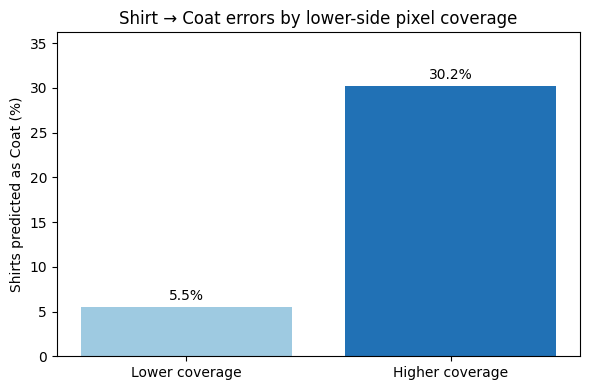

In [15]:
groups = [~higher_coverage, higher_coverage]
rates = [100 * called_coat[group].mean() for group in groups]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Lower coverage", "Higher coverage"], rates,
              color=["#9ecae1", "#2171b5"])
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_ylim(0, max(rates) * 1.2)
ax.set_ylabel("Shirts predicted as Coat (%)")
ax.set_title("Shirt → Coat errors by lower-side pixel coverage")
plt.tight_layout()
plt.show()

In [16]:
shirt_id = class_names.index("Shirt")
called_shirt = predicted[shirt_indices] == shirt_id

for name, group in [
    ("Lower coverage", ~higher_coverage),
    ("Higher coverage", higher_coverage),
]:
    correct = (called_shirt & group).sum()
    total = group.sum()
    print(f"{name}: {correct}/{total} correctly predicted as Shirt ({correct / total:.1%})")

Lower coverage: 303/506 correctly predicted as Shirt (59.9%)
Higher coverage: 205/494 correctly predicted as Shirt (41.5%)


In the Fashion-MNIST test set, shirts with more bright pixels near the lower sides were correctly predicted as Shirt less often (41.5% vs. 59.9%) and were mistaken for Coat more often (30.2% vs. 5.5%). Sleeve length is one possible explanation, but we only measured pixel coverage.